# 03 · EDA – Atendimento e Perfil

**Responsável:** P4 – EDA Atendimento & Perfil

**Perguntas:**
- Como o NPS se relaciona com `customer_service_contacts`, `resolution_time_days` e `complaints_count`?
- Que tipo de cliente tende a ter NPS mais alto ou mais baixo (idade, região, tempo de relacionamento)?
- Como o perfil do pedido (valor, itens, desconto, parcelas) se relaciona com o NPS?
- O que mais gera detratores?

| | Arquivo |
|---|---|
| Entrada | `data/processed/nps_tratado.csv` (gerado pelo notebook 01) |
| Figuras | `reports/figures/` (nomes listados em cada seção) |

**Como ler os números deste notebook:** para cada grupo de clientes são mostrados a **nota média** (0 a 10), a **% de detratores** (nota abaixo de 7) e o **NPS do grupo** (% promotores − % detratores, de −100 a +100). Como a base inteira tem NPS −80, olhar só a nota média pode esconder diferenças; a % de detratores é a medida mais direta de "quantos clientes estamos perdendo".

## 0. Configuração

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Caminhos relativos à raiz do repositório (o notebook roda de dentro de notebooks/)
ROOT = Path.cwd().parent
PROCESSED_PATH = ROOT / "data" / "processed" / "nps_tratado.csv"
FIGURES_DIR = ROOT / "reports" / "figures"

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

In [2]:
# Mesmo estilo de gráfico do notebook 01
COR_SERIE = "#2a78d6"
COR_ALERTA = "#d64545"
COR_NEUTRA = "#c3c2b7"
COR_TEXTO = "#0b0b0b"
COR_TEXTO_SECUNDARIO = "#52514e"
COR_TEXTO_MUDO = "#898781"
COR_GRADE = "#e1e0d9"
COR_EIXO = "#c3c2b7"
COR_FUNDO = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": COR_FUNDO,
    "axes.facecolor": COR_FUNDO,
    "axes.edgecolor": COR_EIXO,
    "axes.labelcolor": COR_TEXTO_SECUNDARIO,
    "axes.titlecolor": COR_TEXTO,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": COR_GRADE,
    "grid.linewidth": 0.8,
    "xtick.color": COR_TEXTO_SECUNDARIO,
    "ytick.color": COR_TEXTO_SECUNDARIO,
    "font.size": 10,
})

## 1. Carga da base tratada

In [3]:
# Sempre partir da base tratada (gerada pelo notebook 01)
df = pd.read_csv(PROCESSED_PATH)
df["nps_category"] = pd.Categorical(
    df["nps_category"], categories=["Detrator", "Neutro", "Promotor"], ordered=True
)

print(f"{df.shape[0]:,} linhas x {df.shape[1]} colunas".replace(",", "."))

2.500 linhas x 25 colunas


### 1.1 Funções de apoio

Duas funções usadas em todas as seções, para que todos os gráficos e tabelas sigam o mesmo padrão:

- `resumir_por_grupo`: tabela com quantidade de pedidos, nota média, % de detratores e NPS de cada grupo.
- `grafico_detratores`: gráfico de barras com a % de detratores por grupo. A linha tracejada é a média da base (84%), para mostrar quais grupos estão acima ou abaixo do normal.

In [4]:
PCT_DETRATORES_BASE = df["is_detractor"].mean() * 100


def calcular_nps(notas):
    """NPS clássico: % promotores (nota ≥ 9) − % detratores (nota < 7)."""
    return ((notas >= 9).mean() - (notas < 7).mean()) * 100


def resumir_por_grupo(grupos):
    """Resumo do NPS para cada valor de `grupos` (uma Series alinhada com df)."""
    resumo = df.groupby(grupos, observed=True)["nps_score"].agg(
        pedidos="size",
        nota_media="mean",
        pct_detratores=lambda notas: (notas < 7).mean() * 100,
        nps=calcular_nps,
    )
    resumo.index.name = grupos.name
    return resumo


def grafico_detratores(resumo, titulo, rotulo_x, eixo=None, destacar_acima=None):
    """Barras com a % de detratores por grupo; grupos acima de `destacar_acima` ficam em vermelho."""
    if eixo is None:
        _, eixo = plt.subplots(figsize=(8, 3.6))
    cores = [
        COR_ALERTA if destacar_acima is not None and valor > destacar_acima else COR_SERIE
        for valor in resumo["pct_detratores"]
    ]
    rotulos = resumo.index.astype(str)
    barras = eixo.bar(rotulos, resumo["pct_detratores"], color=cores)
    eixo.axhline(PCT_DETRATORES_BASE, color=COR_TEXTO_SECUNDARIO, linestyle="--", linewidth=1)
    for barra, valor in zip(barras, resumo["pct_detratores"]):
        eixo.text(barra.get_x() + barra.get_width() / 2, valor + 1.5, f"{valor:.0f}%",
                  ha="center", va="bottom", fontsize=9, color=COR_TEXTO_SECUNDARIO)
    eixo.set_ylim(0, 112)
    eixo.set_title(titulo)
    eixo.set_xlabel(rotulo_x)
    eixo.set_ylabel("% de detratores")
    eixo.grid(axis="x", visible=False)
    return eixo

## 2. NPS x atendimento

### 2.1 Contatos com o atendimento (`customer_service_contacts`)

Clientes com 5 a 7 contatos são poucos (44 no total), então foram agrupados em "5+".

In [5]:
contatos = df["customer_service_contacts"].clip(upper=5).map(lambda n: "5+" if n == 5 else str(n))
contatos = pd.Series(pd.Categorical(contatos, categories=["0", "1", "2", "3", "4", "5+"], ordered=True),
                     index=df.index, name="contatos com o atendimento")

resumo_contatos = resumir_por_grupo(contatos)
resumo_contatos

,pedidos,nota_media,pct_detratores,nps
contatos com o atendimento,,,,
0,554,5.54,70.76,-60.47
1,816,4.66,83.95,-79.53
2,640,4.12,88.59,-86.41
3,314,3.20,93.31,-92.68
4,132,2.65,97.73,-96.97
5+,44,1.93,97.73,-97.73


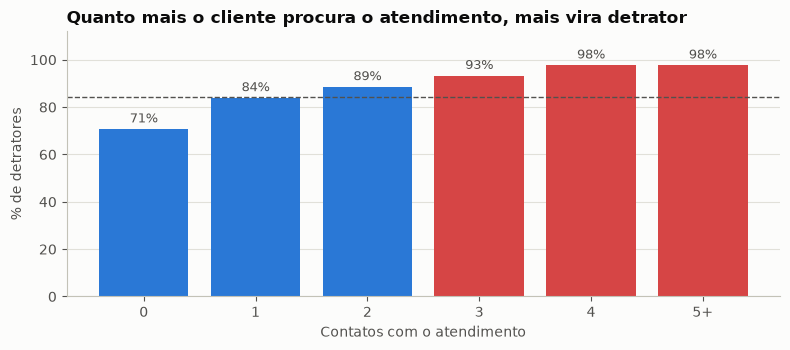

In [6]:
eixo = grafico_detratores(
    resumo_contatos, "Quanto mais o cliente procura o atendimento, mais vira detrator",
    "Contatos com o atendimento", destacar_acima=90,
)
plt.gcf().tight_layout()
plt.gcf().savefig(FIGURES_DIR / "nps_por_contatos_atendimento.png", dpi=150, bbox_inches="tight")
plt.show()

**Leitura:** o cliente que **não precisou falar com o atendimento** é o mais satisfeito da base: nota média 5,5 e 71% de detratores. **Cada contato a mais piora o quadro**: com 1 contato, 84% de detratores; com 3 contatos, 93%; com 4 ou mais, praticamente todos são detratores.

Cada vez que o cliente precisa procurar a empresa é um sinal de que algo deu errado na jornada. O número de contatos funciona como um **termômetro do problema**.

**Figura:** `nps_por_contatos_atendimento.png`

### 2.2 Tempo de resolução (`resolution_time_days`)

In [7]:
resolucao = df["resolution_time_days"].rename("dias para resolver")
resumo_resolucao = resumir_por_grupo(resolucao)
resumo_resolucao

,pedidos,nota_media,pct_detratores,nps
dias para resolver,,,,
0,208,5.32,75.00,-65.38
1,192,5.00,76.04,-68.23
2,229,4.82,81.66,-76.42
3,237,4.63,78.06,-71.31
4,206,4.44,84.95,-79.61
5,176,4.42,85.80,-82.95
6,197,4.32,85.28,-81.22
7,213,4.26,85.92,-83.57
8,227,3.97,88.99,-86.34


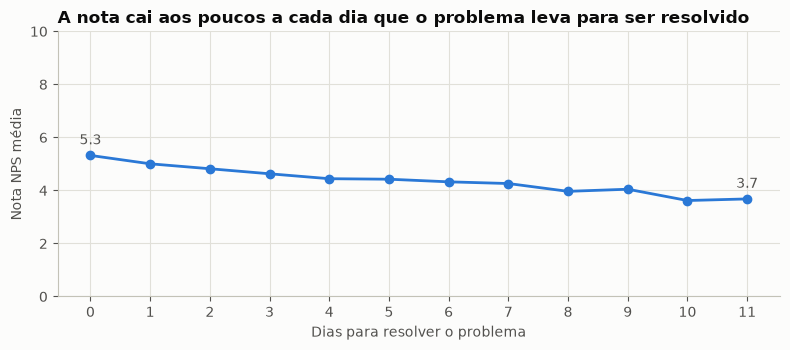

In [8]:
fig, eixo_nota = plt.subplots(figsize=(8, 3.6))
eixo_nota.plot(resumo_resolucao.index, resumo_resolucao["nota_media"], marker="o", color=COR_SERIE, linewidth=2)
eixo_nota.set_ylim(0, 10)
eixo_nota.set_xticks(resumo_resolucao.index)
eixo_nota.set_title("A nota cai aos poucos a cada dia que o problema leva para ser resolvido")
eixo_nota.set_xlabel("Dias para resolver o problema")
eixo_nota.set_ylabel("Nota NPS média")
for dia in (0, 11):
    valor = resumo_resolucao.loc[dia, "nota_media"]
    eixo_nota.annotate(f"{valor:.1f}", (dia, valor), textcoords="offset points", xytext=(0, 8),
                       ha="center", color=COR_TEXTO_SECUNDARIO)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "nps_por_tempo_resolucao.png", dpi=150, bbox_inches="tight")
plt.show()

**Leitura:** o efeito do tempo de resolução é **gradual, sem um ponto de ruptura claro**. A nota média cai de 5,3 (resolvido no mesmo dia) para cerca de 3,7 (10 a 11 dias), e a % de detratores sobe de 75% para cerca de 91%. Cada dia a mais custa pouco, mas os dias se acumulam: um problema que leva 10 dias ou mais para ser resolvido custa cerca de 1,6 ponto na nota.

**Figura:** `nps_por_tempo_resolucao.png`

### 2.3 Resolução sem contato com o atendimento

O notebook 01 marcou 511 pedidos com tempo de resolução, mas sem nenhum contato com o atendimento (`flag_resolution_without_contact`). Esses clientes têm nota **mais alta** que o restante (5,5 x 4,1), o que reforça a leitura da seção 2.1: quando o problema é resolvido **sem o cliente precisar ligar**, a experiência é bem melhor.

In [9]:
resumir_por_grupo(
    df["flag_resolution_without_contact"].map({0: "demais pedidos", 1: "resolvido sem contato"})
    .rename("tipo de resolução")
)

,pedidos,nota_media,pct_detratores,nps
tipo de resolução,,,,
demais pedidos,1989,4.10,87.48,-84.36
resolvido sem contato,511,5.45,72.21,-62.82


## 3. NPS x reclamações (`complaints_count`)

Clientes com 8 a 11 reclamações são poucos (92 no total), então foram agrupados em "8+".

In [10]:
reclamacoes = df["complaints_count"].clip(upper=8).map(lambda n: "8+" if n == 8 else str(n))
reclamacoes = pd.Series(
    pd.Categorical(reclamacoes, categories=[str(n) for n in range(8)] + ["8+"], ordered=True),
    index=df.index, name="reclamações",
)

resumo_reclamacoes = resumir_por_grupo(reclamacoes)
resumo_reclamacoes

,pedidos,nota_media,pct_detratores,nps
reclamações,,,,
0,23,8.52,17.39,21.74
1,122,7.77,30.33,-9.02
2,277,6.05,65.34,-54.15
3,507,4.91,81.66,-77.12
4,600,4.22,89.83,-87.00
5,444,3.65,94.59,-93.92
6,266,3.06,97.37,-97.37
7,169,2.81,97.04,-97.04
8+,92,2.14,98.91,-97.83


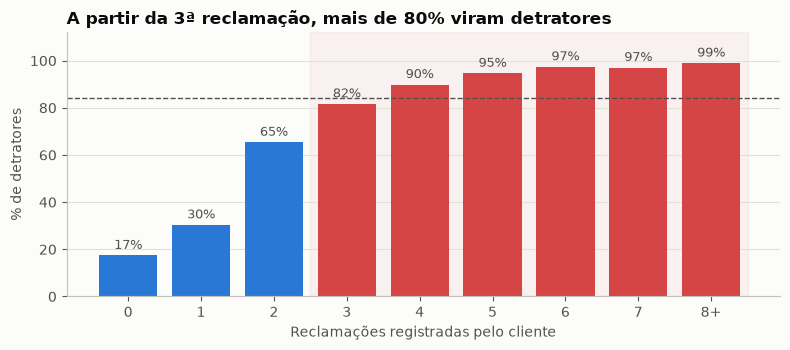

In [11]:
eixo = grafico_detratores(
    resumo_reclamacoes, "A partir da 3ª reclamação, mais de 80% viram detratores",
    "Reclamações registradas pelo cliente", destacar_acima=80,
)
eixo.axvspan(2.5, 8.5, color=COR_ALERTA, alpha=0.06, zorder=0)
plt.gcf().tight_layout()
plt.gcf().savefig(FIGURES_DIR / "nps_por_reclamacoes.png", dpi=150, bbox_inches="tight")
plt.show()

**Leitura:** reclamações são o fator de atendimento com a relação mais forte com o NPS, e aqui existe um **ponto de ruptura**:

- Com **0 ou 1 reclamação**, a maioria dos clientes **não** é detratora (17% e 30%). É o único grupo da base com NPS próximo de zero ou positivo.
- Na **2ª reclamação**, a % de detratores dobra (65%).
- A partir da **3ª reclamação**, mais de 80% são detratores, e a partir da 5ª, praticamente todos.

**Em linguagem de operação:** a segunda reclamação é o último momento em que ainda dá para "salvar" o cliente. Se ele precisou reclamar duas vezes, o caso deveria ser escalado imediatamente.

**Figura:** `nps_por_reclamacoes.png`

### 3.1 Reclamações e contatos andam juntos

Contatos e reclamações têm correlação alta (0,75): quem reclama mais também liga mais. O mapa abaixo cruza os dois para ver qual deles pesa mais.

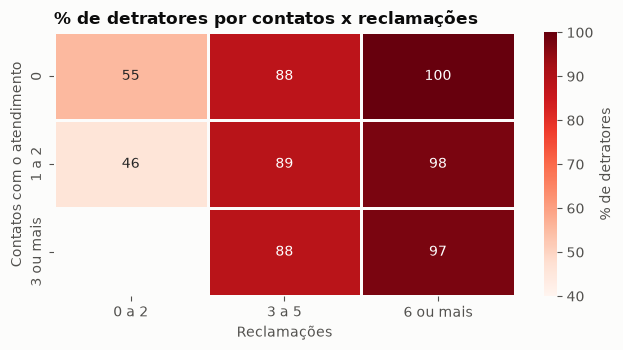

Pedidos em cada célula:


complaints_count,0 a 2,3 a 5,6 ou mais
customer_service_contacts,,,
0,296.00,250.00,8.00
1 a 2,126.00,1164.00,166.00
3 ou mais,NaN,137.00,353.00


In [12]:
faixa_reclamacoes = pd.cut(df["complaints_count"], bins=[0, 3, 6, np.inf], right=False,
                           labels=["0 a 2", "3 a 5", "6 ou mais"])
faixa_contatos = pd.cut(df["customer_service_contacts"], bins=[0, 1, 3, np.inf], right=False,
                        labels=["0", "1 a 2", "3 ou mais"])

mapa_detratores = df.pivot_table(
    index=faixa_contatos, columns=faixa_reclamacoes, values="is_detractor",
    aggfunc="mean", observed=True,
) * 100
mapa_pedidos = df.pivot_table(
    index=faixa_contatos, columns=faixa_reclamacoes, values="is_detractor",
    aggfunc="size", observed=True,
)

fig, eixo = plt.subplots(figsize=(6.5, 3.6))
sns.heatmap(
    mapa_detratores, annot=True, fmt=".0f", cmap="Reds", vmin=40, vmax=100,
    cbar_kws={"label": "% de detratores"}, linewidths=1, linecolor=COR_FUNDO, ax=eixo,
)
eixo.set_title("% de detratores por contatos x reclamações")
eixo.set_xlabel("Reclamações")
eixo.set_ylabel("Contatos com o atendimento")
eixo.grid(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "detratores_contatos_x_reclamacoes.png", dpi=150, bbox_inches="tight")
plt.show()

print("Pedidos em cada célula:")
mapa_pedidos

**Leitura:** olhando **por coluna** (mesmo número de reclamações), a % de detratores muda pouco com o número de contatos. Olhando **por linha** (mesmo número de contatos), ela salta conforme as reclamações aumentam. Ou seja, **a reclamação é o problema; o contato é, em boa parte, o reflexo dela**. O cliente liga porque tem do que reclamar.

Combinação 3+ contatos com 0 a 2 reclamações não existe na base (célula vazia).

**Figura:** `detratores_contatos_x_reclamacoes.png`

### 3.2 De onde vêm as reclamações? (ponte com a EDA logística)

In [13]:
reclamacoes_por_atraso = df.groupby("delivery_delay_days")["complaints_count"].mean().rename("reclamações médias")
contatos_por_atraso = df.groupby("delivery_delay_days")["customer_service_contacts"].mean().rename("contatos médios")
pd.concat([reclamacoes_por_atraso, contatos_por_atraso, df["delivery_delay_days"].value_counts().rename("pedidos")], axis=1)

,reclamações médias,contatos médios,pedidos
delivery_delay_days,,,
0,2.96,1.55,277
1,4.14,1.56,615
2,4.22,1.53,646
3,4.35,1.45,525
4,4.54,1.56,270
5,4.57,1.47,116
6,4.88,1.50,34
7,4.21,1.07,14
8,4.33,1.67,3


**Leitura:** pedidos entregues **no prazo** têm em média 3 reclamações; com **qualquer atraso**, a média sobe para mais de 4. Parte das reclamações, portanto, nasce na logística (tema do notebook 02). Já o número de contatos **não muda** com o atraso, o que sugere que contatos e atraso são problemas distintos, que precisam ser atacados separadamente.

## 4. Perfil do cliente

Faixas de idade e de tempo de relacionamento escolhidas para ter grupos de tamanho razoável (mais de 200 clientes cada).

In [14]:
faixa_idade = pd.cut(df["customer_age"], bins=[18, 25, 35, 45, 55, 70], right=False,
                     labels=["18–24", "25–34", "35–44", "45–54", "55+"]).rename("idade")
faixa_relacionamento = pd.cut(df["customer_tenure_months"], bins=[0, 12, 24, 60, 120], right=False,
                              labels=["< 1 ano", "1–2 anos", "2–5 anos", "5+ anos"]).rename("tempo de relacionamento")
regiao = df["customer_region"].rename("região")

resumos_cliente = {
    "Idade": resumir_por_grupo(faixa_idade),
    "Região": resumir_por_grupo(regiao).sort_values("pct_detratores"),
    "Tempo de relacionamento": resumir_por_grupo(faixa_relacionamento),
}
pd.concat(resumos_cliente)

pedidos  nota_media  pct_detratores  \
Idade                   18–24             344        4.46           84.88   
                        25–34             461        4.65           79.61   
                        35–44             509        4.13           88.41   
                        45–54             480        4.30           84.17   
                        55+               706        4.40           84.42   
Região                  Sul               521        4.49           83.30   
                        Sudeste           520        4.37           83.65   
                        Centro-Oeste      468        4.21           84.19   
                        Norte             506        4.38           85.18   
                        Nordeste          485        4.42           85.57   
Tempo de relacionamento < 1 ano           224        4.17           86.61   
                        1–2 anos          242        4.65           80.99   
                        2–5 anos          719        4.35           85.67   
                        5+ anos          1315        4.38           83.88   

                                        nps  
Idade                   18–24        -80.23  
                        25–34        -74.19  
                        35–44        -84.87  
                        45–54        -80.62  
                        55+          -79.60  
Região                  Sul          -78.89  
                        Sudeste      -79.23  
                        Centro-Oeste -78.85  
                        Norte        -81.62  
                        Nordeste     -81.24  
Tempo de relacionamento < 1 ano      -83.48  
                        1–2 anos     -75.21  
                        2–5 anos     -82.20  
                        5+ anos      -79.01

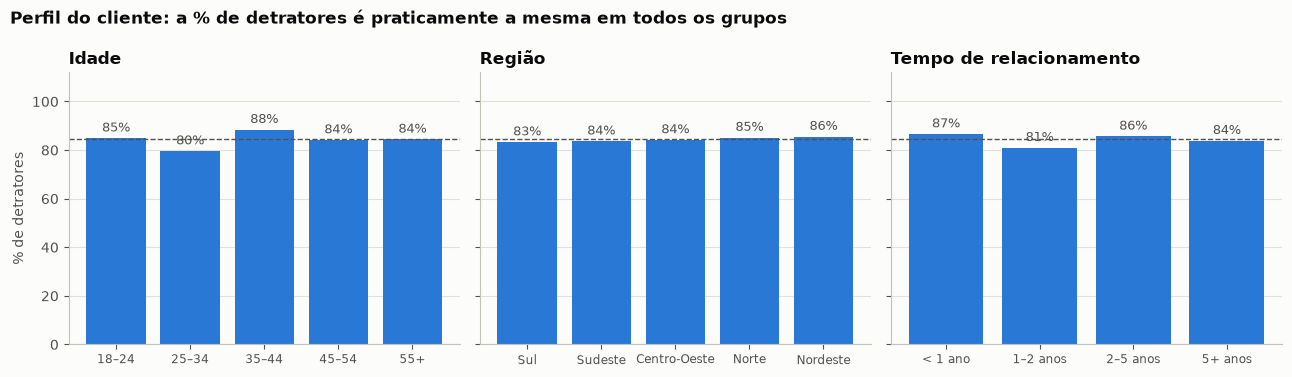

In [15]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for eixo, (nome, resumo) in zip(eixos, resumos_cliente.items()):
    grafico_detratores(resumo, nome, "", eixo=eixo)
    eixo.tick_params(axis="x", labelsize=8.5)
for eixo in eixos[1:]:
    eixo.set_ylabel("")
fig.suptitle("Perfil do cliente: a % de detratores é praticamente a mesma em todos os grupos",
             x=0.01, ha="left", fontweight="bold", color=COR_TEXTO)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "nps_perfil_cliente.png", dpi=150, bbox_inches="tight")
plt.show()

**Leitura:** **não existe um tipo de cliente que seja naturalmente mais satisfeito ou mais insatisfeito.** Em todas as faixas de idade, regiões e tempos de relacionamento, a % de detratores fica entre 79% e 89%, colada na média da base (linha tracejada). As pequenas diferenças (ex.: clientes de 25 a 34 anos um pouco melhores, de 35 a 44 um pouco piores) são do tamanho que se espera por acaso em grupos de algumas centenas de clientes.

Destaque importante para o negócio: **nem clientes antigos são mais tolerantes**. Um cliente com mais de 5 anos de casa vira detrator na mesma proporção que um cliente novo quando a experiência falha. Fidelidade passada não protege contra uma entrega ruim.

**Figura:** `nps_perfil_cliente.png`

## 5. Perfil do pedido

In [16]:
faixa_valor = pd.cut(df["order_value"], bins=[0, 200, 400, 600, 1000, np.inf], right=False,
                     labels=["< R$200", "R$200–400", "R$400–600", "R$600–1.000", "R$1.000+"]).rename("valor do pedido")
faixa_desconto = pd.cut(df["discount_value"], bins=[0, 10, 25, 50, 100, np.inf], right=False,
                        labels=["< R$10", "R$10–25", "R$25–50", "R$50–100", "R$100+"]).rename("desconto")
faixa_parcelas = pd.cut(df["payment_installments"], bins=[1, 2, 4, 7, 10, np.inf], right=False,
                        labels=["à vista", "2–3x", "4–6x", "7–9x", "10x+"]).rename("parcelas")
itens = df["items_quantity"].rename("itens no pedido")

resumos_pedido = {
    "Valor do pedido": resumir_por_grupo(faixa_valor),
    "Itens no pedido": resumir_por_grupo(itens),
    "Desconto": resumir_por_grupo(faixa_desconto),
    "Parcelas": resumir_por_grupo(faixa_parcelas),
}
pd.concat(resumos_pedido)

pedidos  nota_media  pct_detratores    nps
Valor do pedido < R$200          541        4.19           87.25 -84.84
                R$200–400        808        4.46           83.54 -78.71
                R$400–600        574        4.30           85.19 -80.49
                R$600–1.000      441        4.52           81.86 -76.19
                R$1.000+         136        4.53           82.35 -77.94
Itens no pedido 1                409        4.33           83.37 -79.71
                2                418        4.47           82.54 -79.19
                3                462        4.34           85.50 -80.74
                4                408        4.20           85.29 -80.39
                5                404        4.42           84.65 -78.96
                6                399        4.51           84.71 -80.70
Desconto        < R$10           695        4.40           85.18 -80.58
                R$10–25          731        4.29           85.77 -83.31
                R$25–50          616        4.46           81.82 -76.62
                R$50–100         367        4.30           85.01 -77.93
                R$100+            91        4.75           81.32 -79.12
Parcelas        à vista          206        4.31           83.98 -79.13
                2–3x             489        4.22           86.50 -82.62
                4–6x             676        4.37           83.58 -78.40
                7–9x             665        4.51           84.81 -80.60
                10x+             464        4.39           82.76 -78.88

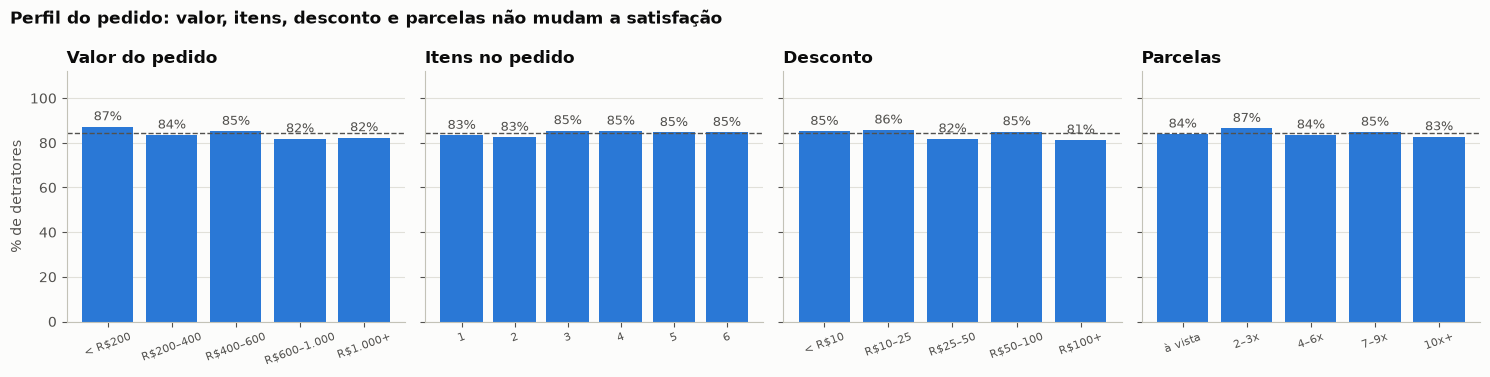

In [17]:
fig, eixos = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for eixo, (nome, resumo) in zip(eixos, resumos_pedido.items()):
    grafico_detratores(resumo, nome, "", eixo=eixo)
    eixo.tick_params(axis="x", labelsize=8, rotation=20)
for eixo in eixos[1:]:
    eixo.set_ylabel("")
fig.suptitle("Perfil do pedido: valor, itens, desconto e parcelas não mudam a satisfação",
             x=0.01, ha="left", fontweight="bold", color=COR_TEXTO)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "nps_perfil_pedido.png", dpi=150, bbox_inches="tight")
plt.show()

**Leitura:** o mesmo padrão do perfil do cliente. **Pedidos caros ou baratos, com 1 ou 6 itens, com ou sem desconto, à vista ou parcelados têm praticamente a mesma % de detratores** (entre 81% e 87%).

O ponto mais útil para o negócio é o **desconto**: clientes que ganharam mais de R$ 100 de desconto não são mais satisfeitos que os que ganharam menos de R$ 10. **Desconto não compra satisfação.** Se a entrega atrasar ou o cliente precisar reclamar, o desconto dado no checkout não evita o detrator.

**Figura:** `nps_perfil_pedido.png`

## 6. O que mais gera detratores?

Para comparar todas as variáveis desta análise na mesma régua, calculamos a **correlação de Spearman** de cada uma com a nota NPS. Em linguagem simples: um número de −1 a +1 que diz o quanto a nota tende a cair (negativo) ou subir (positivo) quando a variável aumenta. Perto de zero = sem relação.

O atraso de entrega (`delivery_delay_days`, analisado no notebook 02) entra no gráfico **só como referência**, para dar a dimensão do atendimento frente à logística.

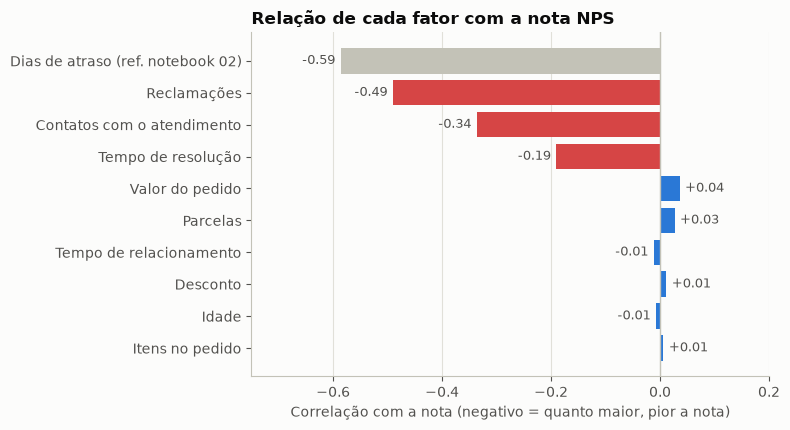

,correlação com a nota
Dias de atraso (ref. notebook 02),-0.59
Reclamações,-0.49
Contatos com o atendimento,-0.34
Tempo de resolução,-0.19
Tempo de relacionamento,-0.01
Idade,-0.01
Itens no pedido,0.01
Desconto,0.01
Parcelas,0.03
Valor do pedido,0.04


In [18]:
NOMES_AMIGAVEIS = {
    "complaints_count": "Reclamações",
    "customer_service_contacts": "Contatos com o atendimento",
    "resolution_time_days": "Tempo de resolução",
    "customer_age": "Idade",
    "customer_tenure_months": "Tempo de relacionamento",
    "order_value": "Valor do pedido",
    "items_quantity": "Itens no pedido",
    "discount_value": "Desconto",
    "payment_installments": "Parcelas",
    "delivery_delay_days": "Dias de atraso (ref. notebook 02)",
}

correlacoes = (
    df[list(NOMES_AMIGAVEIS)].corrwith(df["nps_score"], method="spearman")
    .rename(index=NOMES_AMIGAVEIS)
    .sort_values(key=abs)
)

fig, eixo = plt.subplots(figsize=(8, 4.4))
cores = [
    COR_NEUTRA if "ref." in nome else (COR_ALERTA if abs(valor) >= 0.15 else COR_SERIE)
    for nome, valor in correlacoes.items()
]
eixo.barh(correlacoes.index, correlacoes.values, color=cores)
eixo.axvline(0, color=COR_EIXO, linewidth=1)
for posicao, valor in enumerate(correlacoes.values):
    deslocamento = -0.01 if valor < 0 else 0.01
    eixo.text(valor + deslocamento, posicao, f"{valor:+.2f}", va="center",
              ha="right" if valor < 0 else "left", fontsize=9, color=COR_TEXTO_SECUNDARIO)
eixo.set_xlim(-0.75, 0.2)
eixo.set_title("Relação de cada fator com a nota NPS")
eixo.set_xlabel("Correlação com a nota (negativo = quanto maior, pior a nota)")
eixo.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fatores_nps_atendimento_perfil.png", dpi=150, bbox_inches="tight")
plt.show()

correlacoes.sort_values().to_frame("correlação com a nota")

**Leitura:** o ranking separa as variáveis em dois blocos bem distintos:

1. **Atendimento pesa, e muito.** Reclamações vêm primeiro, seguidas de contatos com o atendimento e, mais atrás, do tempo de resolução. As três têm relação negativa: quanto mais, pior a nota.
2. **Perfil do cliente e do pedido praticamente não pesam.** Idade, tempo de relacionamento, valor, itens, desconto e parcelas ficam todos colados no zero.

Como referência, o atraso de entrega (notebook 02) aparece um pouco acima das reclamações. **Logística e atendimento são, juntos, os dois motores do NPS**.

> **Correlação não é causa.** O gráfico mostra o que anda junto com notas baixas. É bem provável que reclamar e esperar a resolução piorem a experiência, mas parte da relação também pode vir de um terceiro fator (ex.: produto com defeito gera reclamação **e** nota baixa).

## 7. Conclusões para o negócio

Escrito para um(a) gerente de operações, sem estatística:

**1. O que mais gera detratores, do lado do atendimento, é o cliente precisar reclamar.**
Com até 1 reclamação, a maioria dos clientes não é detratora. Na 2ª reclamação, dois em cada três já são. A partir da 3ª, mais de 80%. → **Ação:** tratar a 2ª reclamação de um mesmo pedido como alerta vermelho, com escalonamento automático para um time dedicado e prazo curto de solução.

**2. O melhor atendimento é o que o cliente não precisa acionar.**
Clientes que não falaram com o atendimento têm a melhor nota da base, e os que tiveram o problema resolvido sem ligar também (nota 5,5 x 4,1). Cada contato a mais aumenta a fatia de detratores; com 4 ou mais contatos, quase todos são. → **Ação:** comunicação proativa (avisar sobre atraso antes que o cliente pergunte, rastreio claro) para evitar que ele precise ligar; resolver no primeiro contato (*First Contact Resolution*).

**3. Cada dia de espera pela solução custa um pouco.**
Não existe um prazo mágico, a nota cai aos poucos: de 5,3 quando o problema é resolvido no mesmo dia para cerca de 3,7 quando leva 10 dias ou mais. → **Ação:** definir um SLA de resolução (ex.: até 3 dias) e acompanhar o tempo médio por tipo de problema.

**4. Não existe "cliente difícil": existe experiência ruim.**
Idade, região e tempo de casa não mudam a satisfação. A mesma falha gera o mesmo detrator em qualquer perfil, inclusive entre os clientes mais antigos. → **Ação:** não segmentar ações de NPS por perfil demográfico; segmentar por **o que aconteceu com o pedido** (atraso, reclamação, contatos).

**5. Desconto, parcelamento e valor do pedido não compram satisfação.**
Clientes com desconto alto, pedido caro ou parcelamento longo são tão detratores quanto os demais. → **Ação:** o investimento que hoje vai para desconto tende a ter mais retorno em NPS se for direcionado a cumprir prazo e a resolver reclamações rápido.

**6. Parte das reclamações nasce na entrega.**
Pedidos atrasados acumulam mais reclamações que pedidos no prazo. → **Ação:** atendimento e logística precisam olhar o mesmo painel; reduzir atraso também reduz a fila do atendimento.

### Limitações desta análise

- **Correlação, não causa:** as relações mostradas indicam associação; a confirmação de causa viria de testes (ex.: aplicar a ação proativa em parte dos clientes e comparar).
- **Momento do registro de `complaints_count`:** ainda não está confirmado se a reclamação é registrada antes ou junto com a pesquisa de NPS (README 7.3). Para a EDA isso não muda as conclusões, mas é decisivo para usar a variável no modelo.
- **Base muito detratora (NPS −80):** com 84% de detratores, as diferenças entre perfis ficam comprimidas. Em uma base mais equilibrada, pequenas diferenças de perfil poderiam aparecer.
- **Sem informação de produto, canal ou motivo da reclamação:** não é possível saber **sobre o que** o cliente reclamou, o que limita o detalhamento das ações.